# Van data naar model

**Topic 1 — PXL · machine learning van begin tot eind**

---

We gebruiken een volkstelling uit de Verenigde Staten. Van bijna 50.000 mensen weten we
leeftijd, opleiding, beroep, burgerlijke staat en hoeveel uur ze werken. En we weten of ze
meer of minder dan 50.000 dollar per jaar verdienden.

> **Kunnen we uit de rest van de gegevens voorspellen of iemand boven de 50.000 zit?**

In **deel 1** bouwen we daar klassieke modellen voor. In **deel 2** een neuraal netwerk, op
exact dezelfde data.

> In deze data zitten kolommen als geslacht en etniciteit. Een model dat daarop voorspelt,
> legt verschillen bloot die in de samenleving bestaan, en kan ze versterken als je er
> beslissingen op baseert. We komen daar aan het eind op terug.

---

# Deel 1 — Klassieke modellen

## 0. Setup

Eerst de gereedschapskist. Dit zijn de vier bibliotheken waarmee je in Python vrijwel al het
klassieke machine learning-werk doet.

In [1]:
# pandas: tabellen inlezen en bewerken. Denk "Excel, maar dan in code".
import pandas as pd

# numpy: rekenen met rijen getallen.
import numpy as np

# matplotlib: grafieken tekenen.
import matplotlib.pyplot as plt

# pathlib: netjes met bestandspaden omgaan.
from pathlib import Path

# scikit-learn: de modellen zelf, plus alles eromheen.
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,
)

# Keras gebruiken we pas in deel 2, maar alle imports staan graag op één plek.
import warnings, os
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"      # TensorFlow wat stiller maken
import keras
from keras import layers

# Zorgt dat grafieken in de notebook verschijnen in plaats van in een apart venster.
%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Veel stappen hieronder gebruiken toeval: welke rijen in welke stapel belanden,
# waar een model begint. Met een vaste "seed" krijg jij exact dezelfde getallen
# als op het scherm. Dat maakt resultaten herhaalbaar - en daar hangt in dit vak
# meer van af dan je zou denken.
RANDOM_STATE = 42

print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)
print("keras       ", keras.__version__)

pandas       3.1.1
numpy        2.5.4
scikit-learn 1.9.1
keras        3.15.1


---

## 1. De data binnenhalen en er voor het eerst naar kijken

De dataset staat lokaal gecacht (zie `haal_data.py` in de README), dus je hebt geen internet
nodig.

In [2]:
bestand = Path("data/inkomen.parquet")
if not bestand.exists():
    raise FileNotFoundError(
        "Data niet gevonden. Draai eerst eenmalig:  .venv/bin/python haal_data.py")

df = pd.read_parquet(bestand)

# .shape geeft (aantal rijen, aantal kolommen)
print(f"{df.shape[0]:,} rijen en {df.shape[1]} kolommen")

48,842 rijen en 15 kolommen


In [3]:
# De eerste vijf rijen. Altijd je allereerste handeling: gewoon kijken.
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


### Twee soorten kolommen

Kijk naar wat er in die tabel staat. Er zijn grofweg twee soorten:

**Numerieke kolommen** bevatten getallen waarmee je kunt rekenen. `age` is er zo een: 40 is
echt tien meer dan 30, en het gemiddelde van die twee (35) betekent iets.

**Categorische kolommen** bevatten categorieën. `occupation` is er zo een: "Sales",
"Tech-support", "Farming-fishing". Je kunt daar niet mee rekenen. Het gemiddelde van "Sales" en
"Farming-fishing" bestaat niet.

Dat onderscheid bepaalt bijna alles wat we straks met een kolom doen, dus laten we ze apart
zetten en tellen.

In [4]:
# pandas kent zelf het verschil tussen soorten kolommen ("dtypes").
# We lopen ze langs en tellen hoeveel verschillende waarden er in elke kolom zitten.
overzicht = pd.DataFrame({
    "soort": ["categorisch" if str(df[k].dtype) in ("category", "object") else "numeriek"
              for k in df.columns],
    "verschillende waarden": [df[k].nunique() for k in df.columns],
    "ontbreekt": [int(df[k].isna().sum()) for k in df.columns],
}, index=df.columns)

display(overzicht)

print(f"numerieke kolommen   : {(overzicht['soort'] == 'numeriek').sum()}")
print(f"categorische kolommen: {(overzicht['soort'] == 'categorisch').sum()}")

,soort,verschillende waarden,ontbreekt
age,numeriek,74,0
workclass,categorisch,8,2799
fnlwgt,numeriek,28523,0
education,categorisch,16,0
education-num,numeriek,16,0
marital-status,categorisch,7,0
occupation,categorisch,14,2809
relationship,categorisch,6,0
race,categorisch,5,0
sex,categorisch,2,0


numerieke kolommen   : 6
categorische kolommen: 9


---

## 2. Eerst kijken, dan modelleren

De verleiding is groot om meteen een model te trainen. Doe dat niet. Bijna alle problemen die
later opduiken, zitten hier al in je data.

### 2.1 Wat voorspellen we eigenlijk, en hoe vaak komt het voor?

De kolom `class` is wat we willen voorspellen. In het vak heet dat de **doelvariabele** of
het **label**.

In [5]:
aantallen = df["class"].value_counts()
aandelen = df["class"].value_counts(normalize=True)

print("Hoe vaak komt elke uitkomst voor?\n")
for waarde in aantallen.index:
    print(f"  {str(waarde):8s} {aantallen[waarde]:7,d}   ({aandelen[waarde]:.1%})")

print()
print("Dit is het belangrijkste getal van de hele notebook:")
print(f"  {aandelen.max():.1%} van de mensen zit in de grootste groep.")
print()
print("Waarom? Omdat een model dat ALTIJD die groep gokt, zonder ook maar")
print("één kolom te bekijken, al evenveel procent 'goed' heeft.")
print("Elk model dat we bouwen moet dat verslaan, anders is het waardeloos.")
print("Dat noemen we de BASISLIJN.")

Hoe vaak komt elke uitkomst voor?

  <=50K     37,155   (76.1%)
  >50K      11,687   (23.9%)

Dit is het belangrijkste getal van de hele notebook:
  76.1% van de mensen zit in de grootste groep.

Waarom? Omdat een model dat ALTIJD die groep gokt, zonder ook maar
één kolom te bekijken, al evenveel procent 'goed' heeft.
Elk model dat we bouwen moet dat verslaan, anders is het waardeloos.
Dat noemen we de BASISLIJN.


Onthoud dat getal: **76,1%**. Een model dat 80% haalt klinkt indrukwekkend, maar is nauwelijks
beter dan altijd hetzelfde antwoord geven. Zonder basislijn weet je niet of je iets presteert.

### 2.2 Ontbrekende waarden

Echte data is nooit compleet. Mensen slaan vragen over, systemen falen, velden blijven leeg.
Laten we kijken waar de gaten zitten.

In [6]:
gaten = df.isna().sum()
gaten = gaten[gaten > 0].sort_values(ascending=False)

print("Kolommen met ontbrekende waarden:\n")
for k, n in gaten.items():
    print(f"  {k:16s} {n:5,d} ontbreekt   ({n / len(df):.1%} van de rijen)")

rijen_met_gat = df.isna().any(axis=1).sum()
print()
print(f"In totaal heeft {rijen_met_gat:,} van de {len(df):,} rijen minstens één gat "
      f"({rijen_met_gat / len(df):.1%}).")

Kolommen met ontbrekende waarden:

  occupation       2,809 ontbreekt   (5.8% van de rijen)
  workclass        2,799 ontbreekt   (5.7% van de rijen)
  native-country     857 ontbreekt   (1.8% van de rijen)

In totaal heeft 3,620 van de 48,842 rijen minstens één gat (7.4%).


**Wat doe je daarmee?** Er zijn drie gangbare keuzes, en de juiste hangt af van je situatie:

| aanpak | wanneer | nadeel |
|---|---|---|
| Rijen met gaten weggooien | als het om een handvol rijen gaat | hier zou je 7,4% van je data verliezen |
| Het gat opvullen met een schatting | bij numerieke kolommen (bv. het gemiddelde) | je verzint data die er niet was |
| Van "ontbreekt" een eigen categorie maken | bij categorische kolommen | geen — vaak de eerlijkste optie |

Wij kiezen de derde. En dat is niet alleen gemakzucht: **dat er iets ontbreekt kan zelf
informatie zijn.** Wie geen beroep opgaf, is misschien werkloos of gepensioneerd. Door er een
categorie "Onbekend" van te maken, mag het model dat zelf uitzoeken in plaats van dat wij het
weggooien.

In [7]:
# We werken vanaf hier op een kopie, zodat de oorspronkelijke tabel intact blijft.
# Dat is een goede gewoonte: je wil altijd terug kunnen naar het origineel.
data = df.copy()

for kolom in data.select_dtypes("category").columns:
    if data[kolom].isna().any():
        # Bij een 'category'-kolom moet je een nieuwe categorie eerst aanmelden
        # voor je hem mag gebruiken. Vandaar die twee stappen.
        data[kolom] = data[kolom].cat.add_categories("Onbekend").fillna("Onbekend")

print(f"Ontbrekende waarden over: {int(data.isna().sum().sum())}")
print()
print("De categorie 'Onbekend' telt nu gewoon mee, bijvoorbeeld bij beroep:")
print(data["occupation"].value_counts().head(4).to_string())

Ontbrekende waarden over: 0

De categorie 'Onbekend' telt nu gewoon mee, bijvoorbeeld bij beroep:
occupation
Prof-specialty     6172
Craft-repair       6112
Exec-managerial    6086
Adm-clerical       5611


### 2.3 Niet elke kolom is een voorspeller

Hier maken beginners vaak hun eerste echte fout: alles wat in de tabel staat in het model
gooien. Twee kolommen verdienen een kritische blik.

**`fnlwgt`** staat voor *final weight*. Dat is een technisch gewicht dat het statistiekbureau
gebruikte om hun steekproef naar de hele bevolking op te schalen. Het zegt iets over de
*steekproef*, niet over de *persoon*. Het hoort niet in een model dat over personen gaat.

**`education` en `education-num`** zijn twee versies van hetzelfde. Laten we dat even bekijken,
want het is een leerzaam toeval.

In [8]:
# Voor elk opleidingsniveau: welke getallen komen voor in education-num?
vergelijking = (df.groupby("education", observed=True)["education-num"]
                  .agg(laagste="min", hoogste="max", hoeveel_verschillende="nunique")
                  .sort_values("laagste"))
display(vergelijking.head(8))

print("Kijk naar de laatste kolom: overal een 1.")
print("Elk opleidingsniveau hoort dus bij precies één getal - het zijn")
print("twee schrijfwijzen van dezelfde kolom.")
print()
print("En let op de VOLGORDE van die getallen: 1st-4th krijgt 2, een")
print("doctoraat krijgt 16. Iemand heeft de opleidingen op volgorde gezet.")
print("Dat is precies wat wij straks met de hand gaan doen, en hier is het")
print("al voor ons gedaan.")

,laagste,hoogste,hoeveel_verschillende
education,,,
Preschool,1,1,1
1st-4th,2,2,1
5th-6th,3,3,1
7th-8th,4,4,1
9th,5,5,1
10th,6,6,1
11th,7,7,1
12th,8,8,1


Kijk naar de laatste kolom: overal een 1.
Elk opleidingsniveau hoort dus bij precies één getal - het zijn
twee schrijfwijzen van dezelfde kolom.

En let op de VOLGORDE van die getallen: 1st-4th krijgt 2, een
doctoraat krijgt 16. Iemand heeft de opleidingen op volgorde gezet.
Dat is precies wat wij straks met de hand gaan doen, en hier is het
al voor ons gedaan.


In [9]:
# fnlwgt eruit: geen eigenschap van de persoon.
# education-num eruit: dubbelop met education. We houden de tekstversie,
# omdat we in paragraaf 3 zelf willen laten zien hoe je die omzet.
data = data.drop(columns=["fnlwgt", "education-num"])

print(f"Kolommen over: {data.shape[1]} (was {df.shape[1]})")
print(list(data.columns))

Kolommen over: 13 (was 15)
['age', 'workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'class']


### 2.4 Een paar grafieken

Valt er überhaupt iets te voorspellen? Als geen enkele kolom samenhangt met het inkomen, kan
het beste model ter wereld er niets van maken.

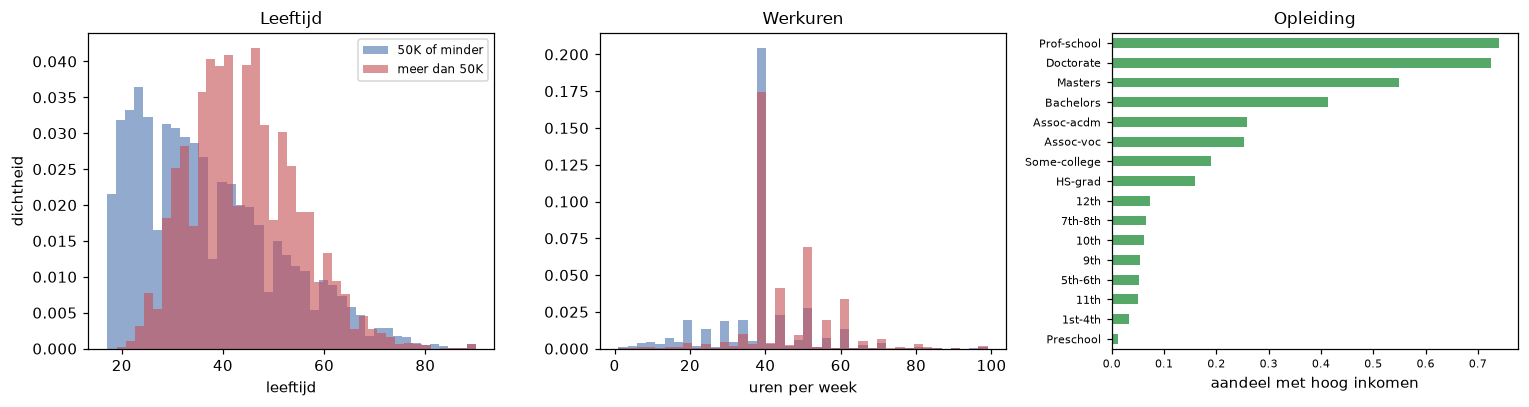

In [10]:
# We maken een 0/1-kolom van de uitkomst: 1 = verdient meer dan 50.000.
# Dat is handig, want dan is "het gemiddelde van die kolom" gelijk aan
# "het aandeel dat boven de 50.000 zit".
data["hoog_inkomen"] = (data["class"] == ">50K").astype(int)

fig, assen = plt.subplots(1, 3, figsize=(14, 3.8))

# --- leeftijd ---
for label, kleur in [(0, "#4C72B0"), (1, "#C44E52")]:
    assen[0].hist(data.loc[data.hoog_inkomen == label, "age"], bins=40, alpha=0.6,
                  color=kleur, density=True,
                  label="meer dan 50K" if label else "50K of minder")
assen[0].set_xlabel("leeftijd"); assen[0].set_ylabel("dichtheid")
assen[0].set_title("Leeftijd", fontsize=11); assen[0].legend(fontsize=8)

# --- uren per week ---
for label, kleur in [(0, "#4C72B0"), (1, "#C44E52")]:
    assen[1].hist(data.loc[data.hoog_inkomen == label, "hours-per-week"], bins=40, alpha=0.6,
                  color=kleur, density=True)
assen[1].set_xlabel("uren per week"); assen[1].set_title("Werkuren", fontsize=11)

# --- opleiding: aandeel hoog inkomen per niveau ---
per_opleiding = (data.groupby("education", observed=True)["hoog_inkomen"]
                     .mean().sort_values())
per_opleiding.plot.barh(ax=assen[2], color="#55A868")
assen[2].set_xlabel("aandeel met hoog inkomen")
assen[2].set_ylabel("")
assen[2].set_title("Opleiding", fontsize=11)
assen[2].tick_params(labelsize=7)

plt.tight_layout(); plt.show()

**Dit is het moment waarop je weet dat er iets te halen valt.** Alle drie de grafieken laten
een duidelijk verband zien: ouder, meer uren, hoger opgeleid gaat samen met vaker boven de
50.000 zitten. Als deze grafieken er vlak hadden uitgezien, had je kunnen stoppen.

Let ook op de staaf bovenaan rechts: bij mensen met een doctoraat zit ruim 70% boven de
50.000, tegen enkele procenten bij wie de lagere school niet afmaakte. Dat is een enorm
verschil — en zulke sterke signalen zijn precies wat een model gaat oppikken.

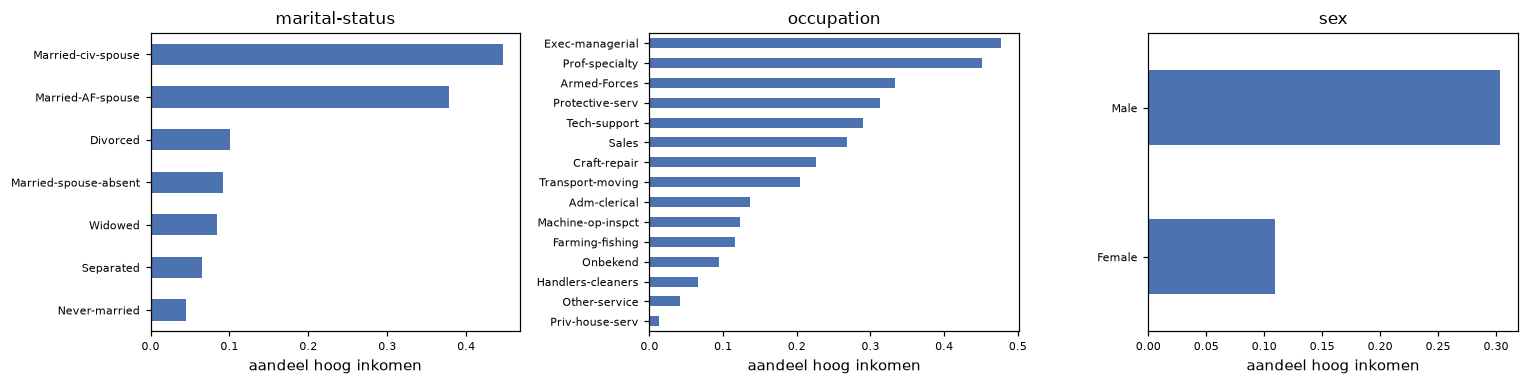

Burgerlijke staat blijkt een van de sterkste signalen in deze data -
sterker dan je op het eerste gezicht zou verwachten.

En kijk naar de rechtergrafiek. Die laat precies zien waarom je bij
dit soort modellen moet opletten: het verschil tussen mannen en vrouwen
in deze data uit 1994 is groot. Een model dat hierop traint, leert dat
verschil en zal het reproduceren.


In [11]:
# Dezelfde vraag voor de categorische kolommen: maakt deze kolom verschil?
fig, assen = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, kolom in zip(assen, ["marital-status", "occupation", "sex"]):
    (data.groupby(kolom, observed=True)["hoog_inkomen"].mean()
         .sort_values().plot.barh(ax=ax, color="#4C72B0"))
    ax.set_xlabel("aandeel hoog inkomen"); ax.set_ylabel("")
    ax.set_title(kolom, fontsize=11); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

print("Burgerlijke staat blijkt een van de sterkste signalen in deze data -")
print("sterker dan je op het eerste gezicht zou verwachten.")
print()
print("En kijk naar de rechtergrafiek. Die laat precies zien waarom je bij")
print("dit soort modellen moet opletten: het verschil tussen mannen en vrouwen")
print("in deze data uit 1994 is groot. Een model dat hierop traint, leert dat")
print("verschil en zal het reproduceren.")

---

## 3. Van tekst naar getallen

Nu komt de stap waar het bij gemengde data altijd om draait.

**Een model kan niet rekenen met het woord "Sales".** Alles wat er in gaat moet een getal zijn.
Dus moeten we elke categorische kolom omzetten. Er zijn twee manieren, en de keuze tussen die
twee is geen detail.

### Manier 1: elke categorie een volgnummer

De luie aanpak: "Sales" wordt 1, "Tech-support" wordt 2, "Farming-fishing" wordt 3.

**Dat is bijna altijd fout.** Want je hebt zojuist tegen je model gezegd dat Tech-support
*tussen* Sales en Farming-fishing in ligt, en dat Farming-fishing drie keer zo veel is als
Sales. Dat is onzin, maar het model heeft geen manier om dat te weten — het ziet alleen
getallen, en getallen hebben nu eenmaal een volgorde.

### Manier 2: one-hot

In plaats van één kolom met volgnummers maak je **één ja/nee-kolom per categorie**:

```
    occupation                occupation_Sales   occupation_Tech-support   occupation_Farming
    ----------                ----------------   -----------------------   ------------------
    Sales              →             1                      0                      0
    Tech-support       →             0                      1                      0
    Farming-fishing    →             0                      0                      1
```

Nu staat er nergens meer een volgorde in. Elke categorie is gewoon aan of uit. Dit heet
**one-hot encoding**: per rij staat er precies één kolom "heet" (op 1).

### Wanneer mag manier 1 dan wél?

Als er **echt** een volgorde in zit. `education` is zo'n geval: een doctoraat is onmiskenbaar
meer onderwijs dan een middelbareschooldiploma. Dan is een volgnummer niet alleen toegestaan,
het is zelfs beter — want het model krijgt die volgorde cadeau in plaats van hem te moeten
afleiden.

Dat heet **ordinale** encodering, en we hebben in §2.3 al gezien dat de makers van deze
dataset het precies zo gedaan hebben.

In [12]:
# Laten we het verschil concreet maken op één kolom.
voorbeeld = data["occupation"].head(6)

# Manier 1: volgnummers. .cat.codes geeft elke categorie een nummer.
volgnummers = voorbeeld.cat.codes

# Manier 2: one-hot. pd.get_dummies maakt per categorie een kolom.
onehot = pd.get_dummies(voorbeeld)

print("De oorspronkelijke kolom:")
print(voorbeeld.to_string())
print("\nManier 1 - volgnummers (let op: dit suggereert een rangorde die er niet is):")
print(volgnummers.to_string())
print(f"\nManier 2 - one-hot: {onehot.shape[1]} kolommen, per rij precies één 1")
display(onehot.astype(int))

De oorspronkelijke kolom:
0    Machine-op-inspct
1      Farming-fishing
2      Protective-serv
3    Machine-op-inspct
4             Onbekend
5        Other-service
Categories (15, str): ['Adm-clerical', 'Armed-Forces', 'Craft-repair', 'Exec-managerial', ..., 'Sales', 'Tech-support', 'Transport-moving', 'Onbekend']

Manier 1 - volgnummers (let op: dit suggereert een rangorde die er niet is):
0     6
1     4
2    10
3     6
4    14
5     7

Manier 2 - one-hot: 15 kolommen, per rij precies één 1


,Adm-clerical,Armed-Forces,Craft-repair,Exec-managerial,Farming-fishing,Handlers-cleaners,Machine-op-inspct,Other-service,Priv-house-serv,Prof-specialty,Protective-serv,Sales,Tech-support,Transport-moving,Onbekend
0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0


### De prijs van one-hot

One-hot heeft één nadeel: je tabel wordt breder. Elke categorie krijgt een eigen kolom, dus
een kolom met 41 verschillende landen levert 41 nieuwe kolommen op.

Laten we kijken wat dat met onze tabel doet.

In [13]:
# De kolommen die we aan het model gaan geven (dus zonder de uitkomst zelf).
X = data.drop(columns=["class", "hoog_inkomen"])
y = data["hoog_inkomen"]

categorisch = X.select_dtypes("category").columns.tolist()
numeriek = X.select_dtypes("number").columns.tolist()

print("Per categorische kolom, hoeveel kolommen one-hot ervan maakt:\n")
for k in categorisch:
    print(f"  {k:16s} {X[k].nunique():3d} categorieën")

# get_dummies doet alle categorische kolommen in één keer.
X_onehot = pd.get_dummies(X, columns=categorisch)

print()
print(f"voor one-hot : {X.shape[1]:3d} kolommen")
print(f"na one-hot   : {X_onehot.shape[1]:3d} kolommen")
print()
print("Van 12 naar 111. Dat is de prijs, en meestal is die prijs het waard.")
print("Maar als je een kolom hebt met duizenden categorieën - klantnummers,")
print("postcodes - dan loopt dit uit de hand en heb je slimmere technieken nodig.")

Per categorische kolom, hoeveel kolommen one-hot ervan maakt:

  workclass          9 categorieën
  education         16 categorieën
  marital-status     7 categorieën
  occupation        15 categorieën
  relationship       6 categorieën
  race               5 categorieën
  sex                2 categorieën
  native-country    42 categorieën

voor one-hot :  12 kolommen
na one-hot   : 106 kolommen

Van 12 naar 111. Dat is de prijs, en meestal is die prijs het waard.
Maar als je een kolom hebt met duizenden categorieën - klantnummers,
postcodes - dan loopt dit uit de hand en heb je slimmere technieken nodig.


---

## 4. Splitsen: waarom je je data in stukken hakt

Nu een idee dat zo belangrijk is dat de rest van het vak erop rust.

Stel dat je een model traint op alle data, en daarna meet hoe goed het is op diezelfde data.
Dan meet je niet of het model iets *geleerd* heeft, maar of het goed kan *onthouden*. Een
model dat alle 48.000 rijen uit zijn hoofd kent, scoort perfect en is volstrekt nutteloos
zodra er iemand nieuw binnenkomt.

Daarom houd je altijd een deel achter.

### Stap 1: train en test

In [14]:
# train_test_split hakt je data in tweeën.
#
#   test_size=0.2     -> 20% gaat opzij als test
#   random_state      -> vaste seed, zodat de split altijd hetzelfde uitvalt
#   stratify=y        -> zorgt dat het aandeel hoge inkomens in BEIDE stapels
#                        gelijk is. Zonder dit kun je door pech een testset
#                        krijgen met veel te weinig hoge inkomens erin.
X_train_vol, X_test, y_train_vol, y_test = train_test_split(
    X_onehot, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"train : {len(X_train_vol):,} rijen  ({y_train_vol.mean():.1%} hoog inkomen)")
print(f"test  : {len(X_test):,} rijen  ({y_test.mean():.1%} hoog inkomen)")
print()
print("Dankzij stratify is dat percentage in beide stapels gelijk.")

train : 39,073 rijen  (23.9% hoog inkomen)
test  : 9,769 rijen  (23.9% hoog inkomen)

Dankzij stratify is dat percentage in beide stapels gelijk.


### Stap 2: en dan loop je tegen een probleem aan

Straks gaan we iets afstellen aan ons model — hoe diep de boom mag worden. We proberen een
paar waardes en kiezen de beste.

Maar kies je die op de **testset**, dan ben je aan het valsspelen. Je gebruikt dan je
examenvragen om te studeren. De score die je uiteindelijk rapporteert is te mooi, want je hebt
precies de instelling gekozen die het op díé rijen goed deed.

**De oplossing is een derde stapel: de validatieset.** Daarop stel je af. De testset raak je
pas aan als alles vastligt, één keer, aan het eind.

| stapel | waarvoor | hoe vaak gebruik je hem |
|---|---|---|
| **train** | het model leert hierop | voortdurend |
| **validatie** | keuzes maken: welke instelling, welk model | zo vaak je wil |
| **test** | het eindoordeel | **één keer**, helemaal aan het eind |

In [15]:
# We splitsen de trainstapel nog eens, in echte train en validatie.
# test_size=0.25 van 80% levert 20% van het totaal op, dus een 60/20/20-verdeling.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_vol, y_train_vol, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train_vol)

print(f"train     : {len(X_train):>6,} rijen  ({len(X_train)/len(X_onehot):.0%})")
print(f"validatie : {len(X_val):>6,} rijen  ({len(X_val)/len(X_onehot):.0%})")
print(f"test      : {len(X_test):>6,} rijen  ({len(X_test)/len(X_onehot):.0%})")
print()
print("Vanaf nu raken we X_test niet meer aan tot paragraaf 6.")

train     : 29,304 rijen  (60%)
validatie :  9,769 rijen  (20%)
test      :  9,769 rijen  (20%)

Vanaf nu raken we X_test niet meer aan tot paragraaf 6.


---

## 5. Het eerste model: een beslisboom

We beginnen met een **beslisboom**, en wel om één reden: het is het enige model dat je
letterlijk kunt uittekenen en voorlezen.

Een beslisboom stelt een reeks ja/nee-vragen. "Is deze persoon getrouwd? Zo ja, is het aantal
jaren onderwijs hoger dan 12? Zo ja, dan gok ik hoog inkomen." Precies zoals een mens een
beslissing zou opschrijven.

Hoe hij die vragen kiest, hoeven we hier niet uit te rekenen. Het idee volstaat: **de boom
zoekt telkens de vraag die de groep het netst in tweeën splitst** — zo veel mogelijk hoge
inkomens aan de ene kant, zo veel mogelijk lage aan de andere.

In [16]:
# max_depth=3 betekent: stel hoogstens 3 vragen achter elkaar.
# Dat is veel te ondiep voor een goed model, maar precies goed om te BEKIJKEN.
boompje = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
boompje.fit(X_train, y_train)       # .fit() = "leer van deze data"

print(f"op de validatieset: {boompje.score(X_val, y_val):.1%}")
print(f"basislijn         : {1 - y.mean():.1%}")

op de validatieset: 82.4%
basislijn         : 76.1%


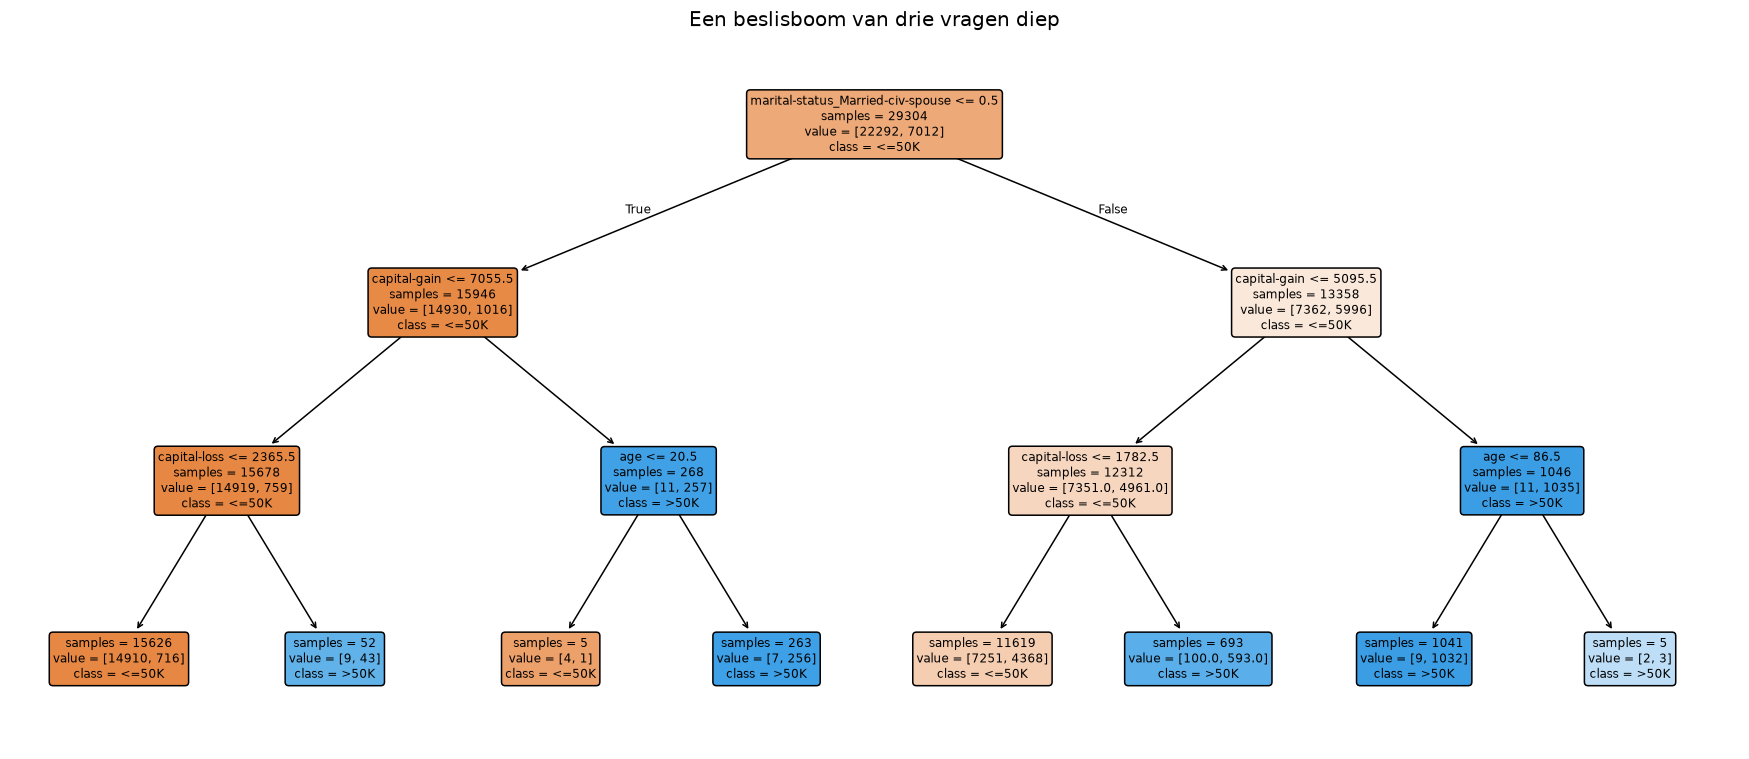

In [17]:
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    boompje,
    feature_names=X_train.columns,
    class_names=["<=50K", ">50K"],
    filled=True,            # kleur de vakjes naar de meerderheidsklasse
    rounded=True,
    fontsize=8,
    impurity=False,         # laat de wiskundige maat weg; die hebben we hier niet nodig
    ax=ax,
)
ax.set_title("Een beslisboom van drie vragen diep", fontsize=13)
plt.tight_layout(); plt.show()

### Lees hem eens hardop

Begin bovenaan en volg een tak naar beneden. In elk vakje staat:

- **de vraag** (bijvoorbeeld `marital-status_Married-civ-spouse <= 0.5`, wat neerkomt op
  "is deze persoon níét getrouwd?")
- **samples**: hoeveel mensen uit de trainset in dit vakje terechtkomen
- **value**: hoe die zich verdelen over lage en hoge inkomens
- **class**: wat de boom hier zou gokken

De kleur zegt het meteen: oranje vakjes zijn overwegend lage inkomens, blauwe overwegend hoge.

Dit is de hele reden om met een boom te beginnen. **Je kunt hem aan iemand uitleggen die nooit
van machine learning gehoord heeft.** Dat lukt je met bijna geen enkel ander model.

### Hoe diep mag hij worden?

Drie vragen is weinig. Wat gebeurt er als we de boom meer ruimte geven? Hier komt de
validatieset in actie: we proberen een reeks dieptes en kijken welke het beste doet op data
die het model niet gezien heeft.

In [18]:
resultaten = []
for diepte in [2, 3, 4, 5, 6, 8, 10, 12, 16, None]:
    model = DecisionTreeClassifier(max_depth=diepte, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    resultaten.append({
        "diepte": "onbeperkt" if diepte is None else diepte,
        "op train": model.score(X_train, y_train),
        "op validatie": model.score(X_val, y_val),
    })

tabel = pd.DataFrame(resultaten).set_index("diepte")
display(tabel.style.format("{:.1%}"))

,op train,op validatie
diepte,,
2,80.4%,80.6%
3,82.2%,82.4%
4,83.5%,83.8%
5,85.1%,85.2%
6,85.5%,85.5%
8,86.1%,85.8%
10,86.8%,85.9%
12,87.5%,85.7%
16,89.7%,85.2%


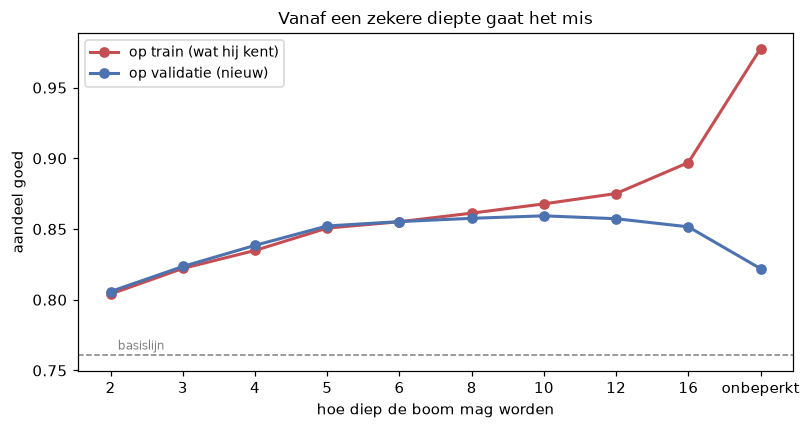

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 4))
x = range(len(tabel))
ax.plot(x, tabel["op train"], "o-", lw=2, label="op train (wat hij kent)", color="#C44E52")
ax.plot(x, tabel["op validatie"], "o-", lw=2, label="op validatie (nieuw)", color="#4C72B0")
ax.axhline(1 - y.mean(), ls="--", color="grey", lw=1)
ax.text(0.1, 1 - y.mean() + 0.004, "basislijn", fontsize=8, color="grey")
ax.set_xticks(x); ax.set_xticklabels(tabel.index)
ax.set_xlabel("hoe diep de boom mag worden"); ax.set_ylabel("aandeel goed")
ax.set_title("Vanaf een zekere diepte gaat het mis", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

### Dit plaatje is het belangrijkste van de hele notebook

Kijk wat er gebeurt als de boom onbeperkt mag groeien:

- **op train** schiet hij naar bijna 98%
- **op validatie** zakt hij naar 82% — slechter dan een boom van vier vragen diep

Dat is **overfitting**, en het is de meest voorkomende manier waarop machine learning misgaat.
De boom is zo diep geworden dat hij de trainingsrijen van buiten leert in plaats van een
patroon te vinden. Hij onthoudt toevalligheden: "die ene 43-jarige loodgieter uit Ohio
verdiende veel, dus 43-jarige loodgieters uit Ohio verdienen veel."

Bij nieuwe mensen heeft hij daar niets aan.

> **De beste score op je trainingsdata is niet je doel.** Hoe goed je model het doet op data
> die het nooit gezien heeft, dát is je doel. En precies daarom bestaat die validatieset.

De rode en blauwe lijn lopen in het begin samen en gaan daarna uit elkaar. **Dat uit elkaar
lopen is het alarmsignaal.** Je kiest de diepte waar de blauwe lijn het hoogst staat.

In [20]:
# Welke diepte won het op de validatieset?
beste = tabel["op validatie"].idxmax()
print(f"beste diepte volgens de validatieset: {beste}")
print(f"  op validatie: {tabel.loc[beste, 'op validatie']:.1%}")
print(f"  op train    : {tabel.loc[beste, 'op train']:.1%}")
print()
print("Let op hoe dicht die twee bij elkaar liggen. Dat is een gezond model:")
print("het presteert op nieuwe data ongeveer even goed als op bekende.")

beste diepte volgens de validatieset: 10
  op validatie: 85.9%
  op train    : 86.8%

Let op hoe dicht die twee bij elkaar liggen. Dat is een gezond model:
het presteert op nieuwe data ongeveer even goed als op bekende.


### De tweede curve: helpt méér data nog?

De vorige grafiek liet zien hoe het model evolueert als je het **complexer** maakt. Er is een
tweede evolutie die minstens zo nuttig is: wat gebeurt er als je het **meer voorbeelden** geeft?

Dat is een vraag met een prijskaartje. Data verzamelen kost geld en tijd, dus je wil weten of
het nog iets oplevert voordat je het doet. De grafiek hieronder beantwoordt dat: we trainen
hetzelfde model op steeds grotere stukken van de trainingsdata en meten telkens twee dingen.

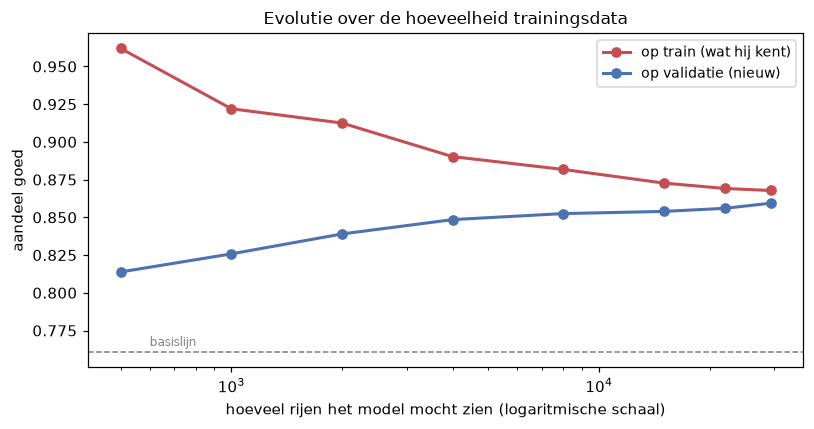

,op train,op validatie
aantal trainrijen,,
500,96.2%,81.4%
1000,92.2%,82.6%
2000,91.2%,83.9%
4000,89.0%,84.9%
8000,88.2%,85.2%
15000,87.3%,85.4%
22000,86.9%,85.6%
29304,86.8%,85.9%


In [21]:
groottes = [500, 1000, 2000, 4000, 8000, 15000, 22000, len(X_train)]
verloop = []

for n in groottes:
    # Telkens de eerste n rijen van de trainset. Die is al door elkaar
    # geschud door train_test_split, dus dit is een eerlijke steekproef.
    model = DecisionTreeClassifier(max_depth=beste, random_state=RANDOM_STATE)
    model.fit(X_train[:n], y_train[:n])
    verloop.append({
        "aantal trainrijen": n,
        "op train": model.score(X_train[:n], y_train[:n]),
        "op validatie": model.score(X_val, y_val),
    })

leercurve = pd.DataFrame(verloop).set_index("aantal trainrijen")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(leercurve.index, leercurve["op train"], "o-", lw=2,
        label="op train (wat hij kent)", color="#C44E52")
ax.plot(leercurve.index, leercurve["op validatie"], "o-", lw=2,
        label="op validatie (nieuw)", color="#4C72B0")
ax.axhline(1 - y.mean(), ls="--", color="grey", lw=1)
ax.text(600, 1 - y.mean() + 0.004, "basislijn", fontsize=8, color="grey")
ax.set_xscale("log")
ax.set_xlabel("hoeveel rijen het model mocht zien (logaritmische schaal)")
ax.set_ylabel("aandeel goed")
ax.set_title("Evolutie over de hoeveelheid trainingsdata", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

display(leercurve.style.format("{:.1%}"))

**Zo lees je deze grafiek.**

Links, met weinig data, staan de twee lijnen ver uit elkaar: het model kent zijn handjevol
rijen bijna perfect maar presteert slecht op nieuwe. Dat is dezelfde overfitting als
hiervoor, nu veroorzaakt door te wéínig voorbeelden in plaats van te veel vragen.

Naar rechts komen ze naar elkaar toe. De rode lijn zakt (het model kan niet meer alles
onthouden) en de blauwe stijgt (het vindt echte patronen). Dat is precies wat je wil zien.

En let op het rechterdeel: **de blauwe lijn vlakt af.** Nog eens tienduizend rijen erbij zou
nauwelijks iets opleveren. Dat is een antwoord dat geld waard is — je weet nu dat je het niet
in méér data moet zoeken, maar in betere kenmerken of een ander model.

> **Waarom staat hier validatie en niet test?** Omdat we deze curve bekíjken om een beslissing
> te nemen, en dat is precies waar de validatieset voor is. Zou je hier je testset invullen,
> dan is je eindoordeel in paragraaf 7 niets meer waard — je hebt er dan al naar gekeken.
> Dezelfde regel als hiervoor, en hij blijft gelden.

---

## 6. Een tweede model ernaast

Een boom is niet het enige wat je kunt doen. We leggen er een **logistische regressie** naast:
een heel ander soort model, dat in plaats van ja/nee-vragen alle kolommen tegelijk afweegt.
Elke kolom krijgt een gewicht, alle gewichten worden opgeteld, en daar rolt een kans uit.

Zo'n model heeft één extra eis: **alle kolommen moeten op vergelijkbare schaal staan.** Leeftijd
loopt van 17 tot 90, `capital-gain` tot boven de 99.000. Zonder ingrijpen zou dat tweede getal
het model domineren, puur omdat het grotere getallen bevat.

Daarom schalen we eerst. `StandardScaler` zet elke kolom om zodat ze rond nul ligt met een
vergelijkbare spreiding. Een boom heeft dat niet nodig — die kijkt alleen naar "groter of
kleiner dan", en dat verandert niet door te schalen.

In [22]:
# BELANGRIJK: de schaler leert alleen van de TRAINdata.
# Zou je hem op alles fitten, dan lekt informatie uit validatie en test
# je voorbewerking binnen. Dat is een klassieke en lastig te vinden fout.
schaler = StandardScaler().fit(X_train)

X_train_geschaald = schaler.transform(X_train)
X_val_geschaald = schaler.transform(X_val)

regressie = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
regressie.fit(X_train_geschaald, y_train)

boom = DecisionTreeClassifier(max_depth=beste, random_state=RANDOM_STATE).fit(X_train, y_train)

print(f"basislijn             : {1 - y.mean():.1%}")
print(f"beslisboom (diepte {beste}) : {boom.score(X_val, y_val):.1%}")
print(f"logistische regressie : {regressie.score(X_val_geschaald, y_val):.1%}")

basislijn             : 76.1%
beslisboom (diepte 10) : 85.9%
logistische regressie : 85.2%


### Waarom we al dat werk met one-hot gedaan hebben

Tijd om terug te komen op §3. We beweerden daar dat categorieën omzetten in volgnummers "bijna
altijd fout" is. Laten we dat niet geloven maar meten: we doen het expres verkeerd en kijken
wat het kost.

In [23]:
# Dezelfde data, maar nu met de LUIE aanpak: elke categorie een volgnummer.
X_lui = X.copy()
for kolom in categorisch:
    X_lui[kolom] = X_lui[kolom].cat.codes        # Sales -> 11, Tech-support -> 13, ...

# Exact dezelfde splitsing, zodat de vergelijking eerlijk is.
Xl_train_vol, Xl_test, yl_train_vol, yl_test = train_test_split(
    X_lui, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
Xl_train, Xl_val, yl_train, yl_val = train_test_split(
    Xl_train_vol, yl_train_vol, test_size=0.25, random_state=RANDOM_STATE, stratify=yl_train_vol)

schaler_lui = StandardScaler().fit(Xl_train)
regressie_lui = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(
    schaler_lui.transform(Xl_train), yl_train)
boom_lui = DecisionTreeClassifier(max_depth=beste, random_state=RANDOM_STATE).fit(Xl_train, yl_train)

vergelijking = pd.DataFrame({
    "met one-hot (goed)": [boom.score(X_val, y_val),
                           regressie.score(X_val_geschaald, y_val)],
    "met volgnummers (fout)": [boom_lui.score(Xl_val, yl_val),
                               regressie_lui.score(schaler_lui.transform(Xl_val), yl_val)],
}, index=["beslisboom", "logistische regressie"])
vergelijking["verschil"] = vergelijking.iloc[:, 0] - vergelijking.iloc[:, 1]

display(vergelijking.style.format("{:.1%}"))

,met one-hot (goed),met volgnummers (fout),verschil
beslisboom,85.9%,85.5%,0.4%
logistische regressie,85.2%,80.3%,4.9%


**Daar zit een les in die je moet onthouden.**

De logistische regressie verliest bijna **5 procentpunt** door die verkeerde encodering. Logisch:
dat model vermenigvuldigt elke kolom met een gewicht en telt alles op. Als "Farming-fishing" een
3 is en "Sales" een 11, dan telt Sales letterlijk bijna vier keer zo zwaar mee — om een reden
die niets met de werkelijkheid te maken heeft.

De beslisboom verliest maar **1,6 procentpunt**. Die kijkt alleen naar "is dit getal groter of
kleiner dan X", en kan met genoeg splitsingen alsnog groepjes categorieën uit elkaar trekken.
Minder gevoelig dus, maar gratis is het niet.

> **De regel die je eruit meeneemt:** je voorbewerking hangt af van je model. Er is niet één
> juiste manier om data klaar te maken — er is een manier die past bij wat je erna doet.

---

## 7. Eén boom is leuk. Wat je in de praktijk gebruikt, is een bos.

Tijd om eerlijk te zijn: niemand zet een enkele beslisboom in productie. We gebruikten hem
omdat je hem kunt uittekenen en voorlezen, en dat is voor leren onbetaalbaar. Maar er is een
model dat vrijwel altijd beter is en dat je net zo makkelijk bouwt.

Herinner je de onbeperkte boom uit §5. Die haalde 97,8% op zijn trainingsdata en zakte naar
82,3% op validatie — hij had alles uit zijn hoofd geleerd en was daardoor waardeloos.

Nu het idee achter een **random forest**:

> **Neem niet één zo'n boom, maar driehonderd. Geef elke boom een andere willekeurige greep uit
> je data en laat hem bij elke splitsing maar een deel van de kolommen bekijken. Laat ze
> allemaal gokken, en neem de meerderheid.**

Waarom dat werkt, zonder wiskunde: elke boom leert zijn eigen toevalligheden uit zijn eigen
stukje data uit het hoofd. Maar ze leren **verschillende** toevalligheden. Als je hun gokken
middelt, vallen die fouten tegen elkaar weg — terwijl het echte patroon, dat ze allemaal
gevonden hebben, blijft staan.

Het is hetzelfde principe als een jury: één rechter kan een eigenaardigheid hebben, twaalf
samen veel minder.

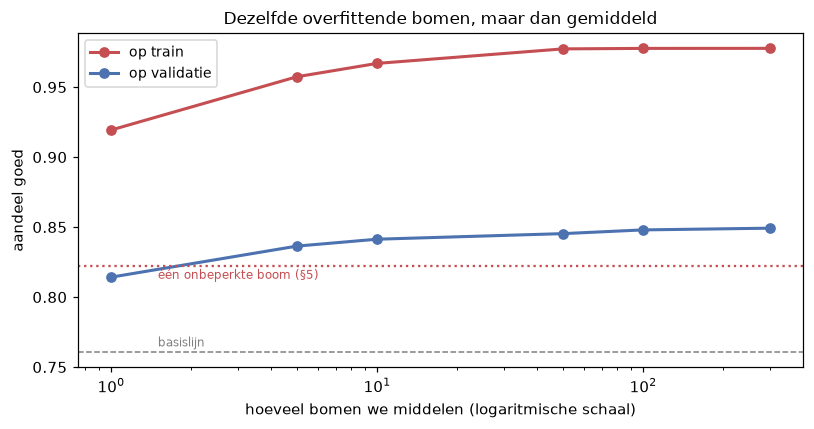

,op train,op validatie
aantal bomen,,
1,91.9%,81.4%
5,95.7%,83.6%
10,96.7%,84.1%
50,97.7%,84.5%
100,97.8%,84.8%
300,97.8%,84.9%


In [24]:
# Eerst het bewijs dat middelen werkt. We nemen EXACT dezelfde onbeperkte
# bomen die in paragraaf 5 zo jammerlijk faalden, en middelen er steeds meer.
rijen = []
for aantal_bomen in [1, 5, 10, 50, 100, 300]:
    bos = RandomForestClassifier(
        n_estimators=aantal_bomen,   # hoeveel bomen
        max_depth=None,              # elk mag onbeperkt diep - dus elk overfit
        n_jobs=-1,                   # gebruik alle processorkernen
        random_state=RANDOM_STATE)
    bos.fit(X_train, y_train)
    rijen.append({
        "aantal bomen": aantal_bomen,
        "op train": bos.score(X_train, y_train),
        "op validatie": bos.score(X_val, y_val),
    })

bostabel = pd.DataFrame(rijen).set_index("aantal bomen")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(bostabel.index, bostabel["op train"], "o-", lw=2,
        label="op train", color="#C44E52")
ax.plot(bostabel.index, bostabel["op validatie"], "o-", lw=2,
        label="op validatie", color="#4C72B0")
ax.axhline(tabel.loc["onbeperkt", "op validatie"], ls=":", color="#C44E52", lw=1.5)
ax.text(1.5, tabel.loc["onbeperkt", "op validatie"] - 0.009,
        "één onbeperkte boom (§5)", fontsize=8, color="#C44E52")
ax.axhline(1 - y.mean(), ls="--", color="grey", lw=1)
ax.text(1.5, 1 - y.mean() + 0.004, "basislijn", fontsize=8, color="grey")
ax.set_xscale("log")
ax.set_xlabel("hoeveel bomen we middelen (logaritmische schaal)")
ax.set_ylabel("aandeel goed")
ax.set_title("Dezelfde overfittende bomen, maar dan gemiddeld", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

display(bostabel.style.format("{:.1%}"))

**Kijk wat daar gebeurt.** De rode lijn blijft op 97,8% plakken — elke boom leert zijn
trainingsdata nog steeds uit het hoofd, daar verandert niets aan. Maar de blauwe lijn klimt
van 82% naar 85%, puur door te middelen.

Dezelfde kapotte bomen. Alleen meer van hen. Dat is het hele idee.

Laten we er tot slot nog wat aan afstellen en dan de eindstand opmaken.

In [25]:
# min_samples_leaf zegt: een eindpunt van een boom moet minstens zoveel
# mensen bevatten. Dat remt het uit-het-hoofd-leren een beetje af,
# bovenop het middelen. We kiezen de waarde op de VALIDATIESET.
scores = {}
for blad in [1, 2, 5, 10, 20]:
    bos = RandomForestClassifier(n_estimators=300, min_samples_leaf=blad,
                                 n_jobs=-1, random_state=RANDOM_STATE)
    bos.fit(X_train, y_train)
    scores[blad] = bos.score(X_val, y_val)
    print(f"  minstens {blad:2d} per eindpunt: validatie {scores[blad]:.1%}")

# De code kiest zelf de winnaar, zodat de tekst nooit uit de pas loopt
# met wat er werkelijk gebeurt.
beste_blad = max(scores, key=scores.get)
print(f"\n-> we gaan verder met minstens {beste_blad} per eindpunt")

  minstens  1 per eindpunt: validatie 84.9%


  minstens  2 per eindpunt: validatie 86.7%


  minstens  5 per eindpunt: validatie 86.6%


  minstens 10 per eindpunt: validatie 86.2%


  minstens 20 per eindpunt: validatie 86.0%

-> we gaan verder met minstens 2 per eindpunt


In [26]:
# De eindstand. Alles nog één keer op train+validatie, dan op de testset.
# Beide modellen nog één keer trainen, nu op train + validatie samen.
# Dat mag: alle keuzes liggen vast, dus je mag alle data gebruiken die
# geen test is. Meer trainingsdata is beter.
boom_eind = DecisionTreeClassifier(max_depth=beste, random_state=RANDOM_STATE)
boom_eind.fit(X_train_vol, y_train_vol)

bos_eind = RandomForestClassifier(n_estimators=300, min_samples_leaf=beste_blad,
                                  n_jobs=-1, random_state=RANDOM_STATE)
bos_eind.fit(X_train_vol, y_train_vol)

eindstand = pd.DataFrame({
    "op de testset": [
        1 - y_test.mean(),
        accuracy_score(y_test, boom_eind.predict(X_test)),
        accuracy_score(y_test, bos_eind.predict(X_test)),
    ]
}, index=["altijd '<=50K' gokken (basislijn)",
          f"één beslisboom (diepte {beste})",
          "random forest (300 bomen)"])

display(eindstand.style.format("{:.2%}"))

print("Het bos wint, maar met een bescheiden marge. En je bent er wel iets")
print("voor kwijt: die boom in paragraaf 5 kon je uittekenen en voorlezen.")
print("Driehonderd bomen kan niemand meer overzien.")
print()
print("Dat is de ruil die je in dit vak voortdurend maakt: nauwkeurigheid")
print("tegen uitlegbaarheid. In topic 3 gaan we een deel van die uitlegbaarheid")
print("terughalen, zonder het bos op te geven.")

,op de testset
altijd '<=50K' gokken (basislijn),76.07%
één beslisboom (diepte 10),86.20%
random forest (300 bomen),86.70%


Het bos wint, maar met een bescheiden marge. En je bent er wel iets
voor kwijt: die boom in paragraaf 5 kon je uittekenen en voorlezen.
Driehonderd bomen kan niemand meer overzien.

Dat is de ruil die je in dit vak voortdurend maakt: nauwkeurigheid
tegen uitlegbaarheid. In topic 3 gaan we een deel van die uitlegbaarheid
terughalen, zonder het bos op te geven.


---

## 8. Is dit nu goed?

We hebben een model dat rond de 86% haalt tegen een basislijn van 76%. Maar "86% goed" is een
misleidend getal, en nu gaan we zien waarom.

Nu halen we de testset erbij. Alle keuzes liggen vast: de diepte is gekozen op validatie,
de voorbewerking staat. Dit is het eindoordeel, en we mogen het maar één keer vellen.

In [27]:
# We kijken naar het random forest uit paragraaf 7 - dat is het model
# dat je in de praktijk zou inzetten. Het is al getraind op train+validatie.
voorspeld = bos_eind.predict(X_test)

print(f"basislijn                 : {1 - y_test.mean():.1%}")
print(f"het random forest op TEST : {accuracy_score(y_test, voorspeld):.1%}")
print()
print(f"Winst ten opzichte van altijd hetzelfde gokken: "
      f"{accuracy_score(y_test, voorspeld) - (1 - y_test.mean()):+.1%}")

basislijn                 : 76.1%
het random forest op TEST : 86.7%

Winst ten opzichte van altijd hetzelfde gokken: +10.6%


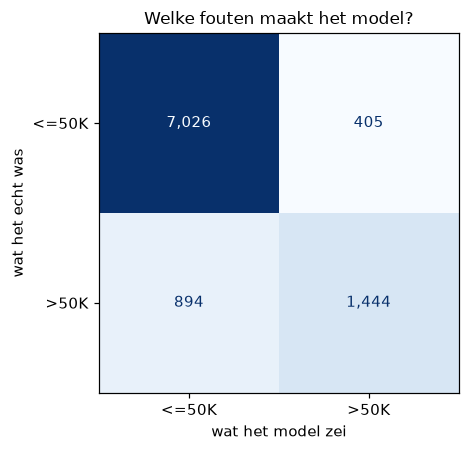

  7,026  terecht 'laag' gezegd
  1,444  terecht 'hoog' gezegd
    405  ten onrechte 'hoog' gezegd
    894  ten onrechte 'laag' gezegd   <- de grootste foutengroep


In [28]:
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, voorspeld, display_labels=["<=50K", ">50K"],
    cmap="Blues", colorbar=False, ax=ax, values_format=",d")
ax.set_xlabel("wat het model zei"); ax.set_ylabel("wat het echt was")
ax.set_title("Welke fouten maakt het model?", fontsize=11)
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, voorspeld).ravel()
print(f"  {tn:>5,d}  terecht 'laag' gezegd")
print(f"  {tp:>5,d}  terecht 'hoog' gezegd")
print(f"  {fp:>5,d}  ten onrechte 'hoog' gezegd")
print(f"  {fn:>5,d}  ten onrechte 'laag' gezegd   <- de grootste foutengroep")

### Het getal achter het getal

Kijk naar die laatste regel. Van de mensen die écht boven de 50.000 zaten, mist het model er een
flink deel. Toch is de totale score 85%.

Dat komt doordat accuracy alle fouten even zwaar telt, terwijl de groepen heel ongelijk zijn.
Er zijn drie keer zoveel lage als hoge inkomens, dus je kunt een heleboel hoge inkomens missen
en nog steeds hoog scoren.

`classification_report` splitst dat uit in twee getallen per groep:

- **precisie** — van alle keren dat het model "hoog" zei, hoe vaak klopte dat?
- **recall** — van alle mensen die écht hoog zaten, hoeveel heeft het model er gevonden?

In [29]:
print(classification_report(y_test, voorspeld, target_names=["<=50K", ">50K"], digits=3))
print("Lees de regel '>50K':")
print("  precisie = als het model 'hoog' zegt, hoe vaak heeft het gelijk")
print("  recall   = welk deel van de echte hoge inkomens vindt het")
print()
print("Die twee lopen uit elkaar, en welke van de twee je belangrijk vindt,")
print("hangt af van wat je met het model gaat doen. Dat is geen technische")
print("vraag maar een vraag over de toepassing.")

              precision    recall  f1-score   support

       <=50K      0.887     0.945     0.915      7431
        >50K      0.781     0.618     0.690      2338

    accuracy                          0.867      9769
   macro avg      0.834     0.782     0.803      9769
weighted avg      0.862     0.867     0.861      9769

Lees de regel '>50K':
  precisie = als het model 'hoog' zegt, hoe vaak heeft het gelijk
  recall   = welk deel van de echte hoge inkomens vindt het

Die twee lopen uit elkaar, en welke van de twee je belangrijk vindt,
hangt af van wat je met het model gaat doen. Dat is geen technische
vraag maar een vraag over de toepassing.


---

# Deel 2 — Een neuraal netwerk

Je random forest haalt ruim 86%. **Dat is de meetlat.**

Levert een neuraal netwerk hier meer op? Zelfde data, zelfde splitsing, zelfde kolommen —
alleen het model verandert. Zo weet je aan het eind zeker dat een verschil door het model komt
en niet door iets anders.

## 9. Wat is een neuraal netwerk eigenlijk?

Vergeet het woord "neuraal" even. Dat komt uit een vergelijking met de hersenen die inmiddels
meer verwarring sticht dan ze oplost.

Wat het werkelijk is:

> **Een stapel rekenlagen. Elke laag neemt een rij getallen aan, mengt die op een hoop
> verschillende manieren door elkaar, en geeft een nieuwe rij getallen door aan de volgende
> laag. De laatste laag geeft je antwoord.**

Het leren bestaat eruit dat het netwerk de mengverhoudingen bijstelt - duizenden kleine
draaiknopjes - tot de antwoorden kloppen.

Vergelijk het met de beslisboom uit deel 1. Die stelde een handvol scherpe ja/nee-vragen. Een
netwerk doet iets heel anders: het weegt **alle** kolommen tegelijk, een beetje, in laag na
laag. Daardoor kan het subtielere combinaties oppikken - maar je kunt het ook niet meer
uittekenen en voorlezen.

### Nu de stap die voor een netwerk wél verplicht is

In deel 1 was schalen optioneel: een beslisboom kijkt alleen of een getal groter of kleiner
is dan een grens, en dat verandert niet als je alles door honderd deelt.

Voor een netwerk ligt dat anders. Dat **vermenigvuldigt** alle getallen met gewichten en telt
ze op. Staat `capital-gain` in tienduizenden en `age` in tientallen, dan overstemt de eerste
de tweede volledig — niet omdat hij belangrijker is, maar omdat hij toevallig grotere getallen
bevat.

Erger nog: zonder schalen komt het netwerk vaak helemaal niet op gang. De eerste berekeningen
leveren dan enorme getallen op, en het leerproces slaat op hol.

**Schalen is bij een netwerk dus geen verfijning maar een voorwaarde.**

In [30]:
# StandardScaler zet elke kolom om zodat hij rond nul ligt met een
# vergelijkbare spreiding.
#
# LET OP: .fit() alleen op de trainset. Zou je hem op alles fitten, dan
# lekt informatie uit validatie en test je voorbewerking in. Dezelfde
# regel als in deel 1, en hier net zo belangrijk.
# De schaler uit paragraaf 6 is al gefit op X_train; we hergebruiken hem.
# Keras rekent met float32, dus we zetten alles meteen om.
X_train_s = schaler.transform(X_train).astype("float32")
X_val_s   = schaler.transform(X_val).astype("float32")
X_test_s  = schaler.transform(X_test).astype("float32")

print("Voor en na schalen, drie kolommen:\n")
vergelijk = pd.DataFrame({
    "voor - gemiddelde": X_train[["age", "capital-gain", "hours-per-week"]].mean(),
    "voor - spreiding": X_train[["age", "capital-gain", "hours-per-week"]].std(),
})
kolomnrs = [X_train.columns.get_loc(k) for k in ["age", "capital-gain", "hours-per-week"]]
vergelijk["na - gemiddelde"] = X_train_s[:, kolomnrs].mean(axis=0)
vergelijk["na - spreiding"] = X_train_s[:, kolomnrs].std(axis=0)
display(vergelijk.round(2))

print("Alle kolommen staan nu op dezelfde schaal. Geen enkele kolom kan het")
print("netwerk nog domineren puur omdat zijn getallen groter zijn.")

Voor en na schalen, drie kolommen:



,voor - gemiddelde,voor - spreiding,na - gemiddelde,na - spreiding
age,38.69,13.72,0.0,1.0
capital-gain,1058.97,7335.77,0.0,1.0
hours-per-week,40.53,12.42,0.0,1.0


Alle kolommen staan nu op dezelfde schaal. Geen enkele kolom kan het
netwerk nog domineren puur omdat zijn getallen groter zijn.


---

## 9.1 Hoe een netwerk eruitziet

Voor we er een bouwen, eerst het plaatje. We maken een netwerk met drie lagen.

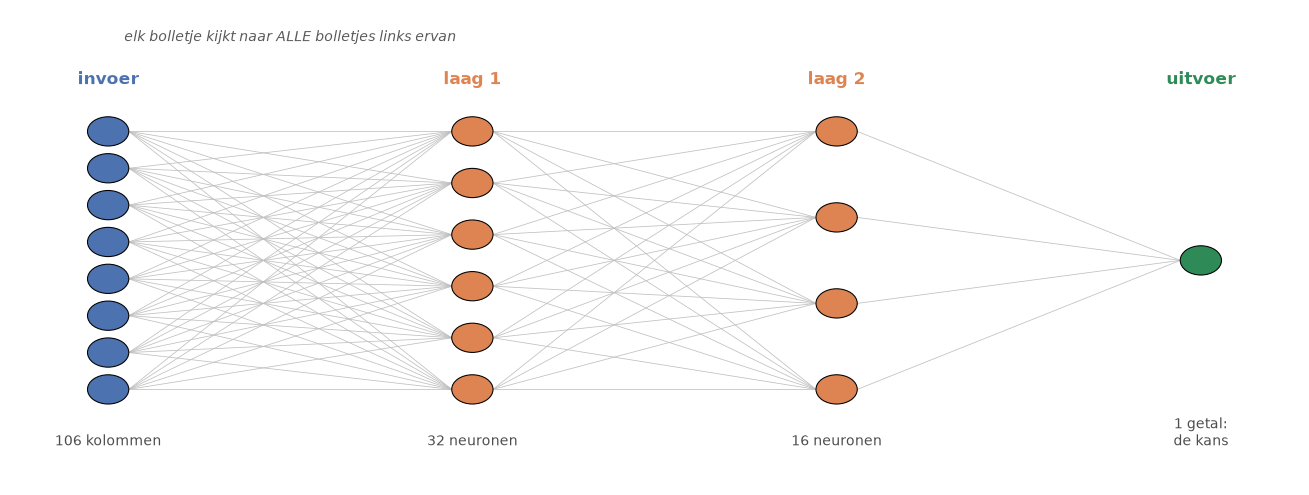

In [31]:
fig, ax = plt.subplots(figsize=(12, 4.6))

lagen = [("invoer", X_onehot.shape[1], 8, "#4C72B0"),
         ("laag 1", 32, 6, "#DD8452"),
         ("laag 2", 16, 4, "#DD8452"),
         ("uitvoer", 1, 1, "#2E8B57")]

posities = []
for k, (naam, echt_aantal, teken_aantal, kleur) in enumerate(lagen):
    x = k * 3.0
    ys = np.linspace(-1.5, 1.5, teken_aantal) if teken_aantal > 1 else [0.0]
    posities.append([(x, yy) for yy in ys])
    for yy in ys:
        ax.add_patch(plt.Circle((x, yy), 0.17, facecolor=kleur, edgecolor="black", lw=0.7,
                                zorder=3))
    ax.text(x, 2.05, naam, ha="center", fontsize=11, fontweight="bold", color=kleur)
    label = f"{echt_aantal} kolommen" if k == 0 else (
            "1 getal:\nde kans" if k == 3 else f"{echt_aantal} neuronen")
    ax.text(x, -2.15, label, ha="center", fontsize=9, color="0.3")

# alle verbindingen tekenen
for links, rechts in zip(posities, posities[1:]):
    for (x1, y1) in links:
        for (x2, y2) in rechts:
            ax.plot([x1 + 0.17, x2 - 0.17], [y1, y2], color="0.75", lw=0.5, zorder=1)

ax.text(1.5, 2.55, "elk bolletje kijkt naar ALLE bolletjes links ervan",
        ha="center", fontsize=9, style="italic", color="0.35")
ax.set_xlim(-0.8, 9.8); ax.set_ylim(-2.6, 2.9); ax.axis("off")
plt.tight_layout(); plt.show()

### Wat gebeurt er in zo'n bolletje?

Eén neuron doet iets heel simpels, in drie stappen:

1. **Het kijkt naar alle getallen die binnenkomen** — alle 111 kolommen, of alle 32 uitkomsten
   van de laag ervoor.
2. **Het weegt ze.** Elk binnenkomend getal krijgt een gewicht: deze telt zwaar mee, die
   nauwelijks, die negatief. Alles wordt opgeteld tot één getal.
3. **Het laat dat getal door een drempel.** Is de som negatief, dan geeft het neuron nul door.
   Is hij positief, dan geeft het de som door. Die regel heet **ReLU**, en meer is het niet.

Die derde stap lijkt onbenullig maar is cruciaal. Zonder dat knikje zouden alle lagen samen
niets meer kunnen dan één grote optelsom — dan had je net zo goed de logistische regressie uit
deel 1 kunnen nemen. **Het is dat knikje dat een netwerk in staat stelt kromme verbanden te
leren.**

En de **gewichten** zijn wat er geleerd wordt. Die beginnen willekeurig en worden tijdens het
trainen duizenden keren een beetje bijgesteld. Ons netwerk heeft er zo'n vierduizend.

---

## 10. Het netwerk bouwen

In Keras is dat bijna letterlijk de tekening opschrijven.

In [32]:
keras.utils.set_random_seed(RANDOM_STATE)

netwerk = keras.Sequential([
    # Sequential = "een rechte stapel lagen, de een na de ander".

    # De invoerlaag zegt alleen hoe breed een rij is. Hier gebeurt nog niets.
    keras.Input(shape=(X_onehot.shape[1],), name="invoer"),

    # Dense = "elk neuron kijkt naar alles van de vorige laag" (de lijnen in de tekening).
    # 32 = het aantal neuronen. activation="relu" is het knikje van hierboven.
    layers.Dense(32, activation="relu", name="laag_1"),

    # Nog een laag, smaller. Elke laag vat samen wat de vorige gevonden heeft.
    layers.Dense(16, activation="relu", name="laag_2"),

    # De uitvoerlaag: één neuron, want we willen één antwoord.
    # activation="sigmoid" perst de uitkomst tussen 0 en 1, zodat je hem
    # als kans kunt lezen: 0.8 betekent "80% kans op meer dan 50.000".
    layers.Dense(1, activation="sigmoid", name="uitvoer"),
], name="inkomensvoorspeller")

netwerk.summary()

Model: "inkomensvoorspeller"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ laag_1 (Dense)                  │ (None, 32)             │         3,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ laag_2 (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ uitvoer (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

**Kijk naar de kolom `Param #` in die samenvatting.** Dat zijn de draaiknopjes: 3.584 in de
eerste laag, 528 in de tweede, 17 in de laatste. Samen ruim vierduizend getallen die het
netwerk tijdens het trainen moet instellen.

Ter vergelijking: de beslisboom uit deel 1 had een paar honderd splitsingen. Dit model heeft
tien keer zoveel vrijheid — en straks zullen we zien dat meer vrijheid niet automatisch beter
betekent.

### Het netwerk klaarmaken om te leren

Voor je kunt trainen moet je drie dingen vastleggen. `compile()` doet dat.

In [33]:
netwerk.compile(
    # DE VERLIESFUNCTIE: hoe meet je hoe fout een voorspelling is?
    # binary_crossentropy straft vooral zelfverzekerde fouten af. Zeg je
    # "95% zeker hoog inkomen" terwijl het laag is, dan is de straf veel
    # groter dan wanneer je "55%" had gezegd. Dat is precies wat je wil:
    # het netwerk leert niet alleen gokken, maar ook twijfelen.
    loss="binary_crossentropy",

    # DE OPTIMIZER: hoe stel je de knopjes bij na elke fout?
    # Adam is de standaardkeuze en werkt bijna altijd goed. De learning
    # rate (1e-3 = 0.001) bepaalt hoe grote stappen hij zet. Te groot en
    # hij schiet door; te klein en het duurt eeuwig.
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),

    # DE MAATSTAF: wat wil JIJ zien tijdens het trainen?
    # Hier niet op gestuurd - puur om mee te kijken.
    metrics=["accuracy"],
)

print("Netwerk klaar om te trainen.")

Netwerk klaar om te trainen.


---

## 11. Trainen, en de evolutie volgen

Nu het echte werk. Twee begrippen die je moet kennen:

**Epoch** — één keer de volledige trainingsdata doorlopen. Na een epoch heeft het netwerk alle
29.304 rijen één keer gezien en zijn knopjes bijgesteld. We doen er zestig.

**Batch size** — het netwerk stelt niet bij na elke rij, maar na elk groepje van 64. Dat is
sneller en de bijstelling wordt rustiger, omdat één rare rij het gemiddelde van 64 niet ver
meesleept.

Het belangrijkste staat in de regel `validation_data`. Daarmee meet Keras na **elke** epoch
hoe het netwerk het doet op data die het niet traint.

In [34]:
geschiedenis = netwerk.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),   # na elke epoch ook hierop meten
    epochs=60,
    batch_size=64,
    verbose=0,                          # geen voortgangsbalk; we tekenen het zo
)

# fit() geeft een object terug met per epoch vier getallen.
verloop = pd.DataFrame(geschiedenis.history)
verloop.index = range(1, len(verloop) + 1)
verloop.index.name = "epoch"

print(f"{len(verloop)} epochs getraind. De eerste en de laatste drie:\n")
display(pd.concat([verloop.head(3), verloop.tail(3)]).round(4))

60 epochs getraind. De eerste en de laatste drie:



,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.8239,0.3757,0.8460,0.3308
2,0.8462,0.3252,0.8524,0.3210
3,0.8513,0.3154,0.8530,0.3179
58,0.8761,0.2643,0.8475,0.3526
59,0.8755,0.2640,0.8477,0.3537
60,0.8758,0.2637,0.8472,0.3534


### De grafiek waar het om draait

Dit is de belangrijkste plaat van deze notebook. Links het **verlies** (hoe fout het netwerk
zit, lager is beter), rechts de **accuracy** (hoe vaak het goed zit, hoger is beter). In beide
grafieken staan twee lijnen: de trainingsdata en de validatiedata.

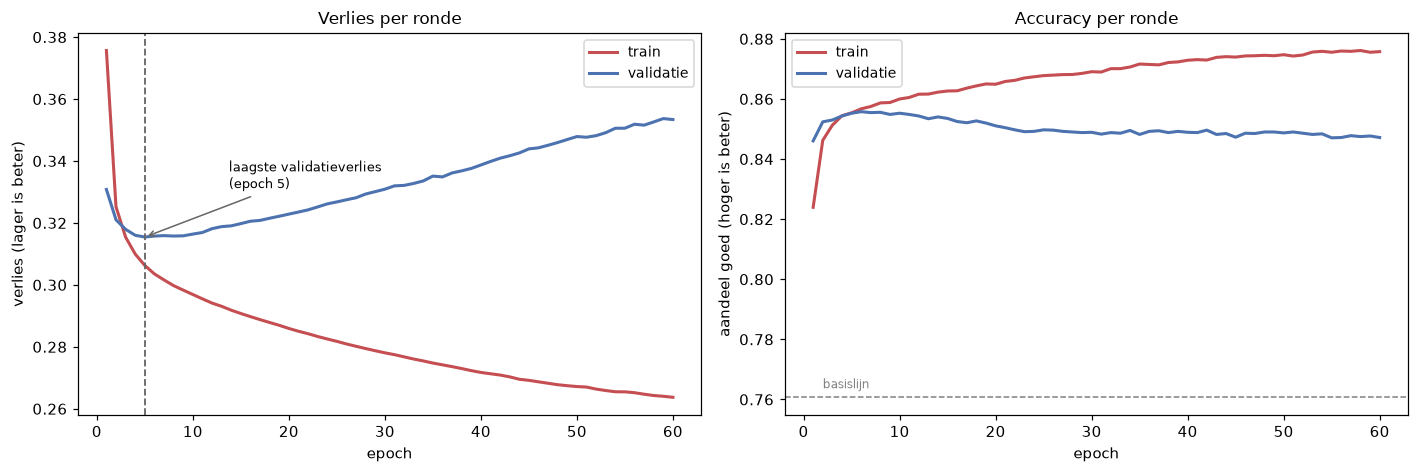

In [35]:
fig, (links, rechts) = plt.subplots(1, 2, figsize=(13, 4.4))

beste_epoch = verloop["val_loss"].idxmin()

# --- links: verlies ---
links.plot(verloop.index, verloop["loss"], lw=2, color="#C44E52", label="train")
links.plot(verloop.index, verloop["val_loss"], lw=2, color="#4C72B0", label="validatie")
links.axvline(beste_epoch, ls="--", color="0.4", lw=1.2)
links.annotate(f"laagste validatieverlies\n(epoch {beste_epoch})",
               (beste_epoch, verloop.loc[beste_epoch, "val_loss"]),
               textcoords="offset points", xytext=(55, 32), fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color="0.4"))
links.set_xlabel("epoch"); links.set_ylabel("verlies (lager is beter)")
links.set_title("Verlies per ronde", fontsize=11); links.legend(fontsize=9)

# --- rechts: accuracy ---
rechts.plot(verloop.index, verloop["accuracy"], lw=2, color="#C44E52", label="train")
rechts.plot(verloop.index, verloop["val_accuracy"], lw=2, color="#4C72B0", label="validatie")
rechts.axhline(1 - y.mean(), ls="--", color="grey", lw=1)
rechts.text(2, 1 - y.mean() + 0.003, "basislijn", fontsize=8, color="grey")
rechts.set_xlabel("epoch"); rechts.set_ylabel("aandeel goed (hoger is beter)")
rechts.set_title("Accuracy per ronde", fontsize=11); rechts.legend(fontsize=9)

plt.tight_layout(); plt.show()

### Lees die linkergrafiek nog eens goed

In het begin dalen beide lijnen: het netwerk leert, en wat het leert geldt ook voor nieuwe
mensen. Dat is gezond.

Maar rond epoch **{beste}** gebeurt er iets. De rode lijn blijft dalen, de blauwe gaat
**omhoog**. Vanaf dat punt wordt het netwerk nog steeds beter in zijn trainingsdata, maar
*slechter* op mensen die het niet kent.

Dat is **overfitting**, en dit is de duidelijkste manier waarop je hem ooit zult zien. In topic
1 zag je hetzelfde gebeuren toen de boom te diep werd. Hier zie je het **tijdens het leren**,
ronde voor ronde.

> De beeldspraak die blijft hangen: het netwerk is de antwoorden van het oefenexamen uit zijn
> hoofd gaan leren in plaats van de stof te begrijpen. Op het oefenexamen scoort het daardoor
> steeds beter. Op het echte examen niet.

**Alles rechts van die stippellijn is verspilde tijd die je model slechter maakt.**

In [36]:
print(f"beste epoch (laagste validatieverlies): {beste_epoch}")
print()
print(f"                    epoch {beste_epoch:<2d}      epoch {len(verloop)}")
print(f"  verlies train  :  {verloop.loc[beste_epoch,'loss']:.4f}      "
      f"{verloop.loc[len(verloop),'loss']:.4f}   <- blijft dalen")
print(f"  verlies valid. :  {verloop.loc[beste_epoch,'val_loss']:.4f}      "
      f"{verloop.loc[len(verloop),'val_loss']:.4f}   <- gaat OMHOOG")
print()
print(f"  accuracy train :  {verloop.loc[beste_epoch,'accuracy']:.1%}       "
      f"{verloop.loc[len(verloop),'accuracy']:.1%}")
print(f"  accuracy valid.:  {verloop.loc[beste_epoch,'val_accuracy']:.1%}       "
      f"{verloop.loc[len(verloop),'val_accuracy']:.1%}")
print()
print("Het netwerk is op het eind beter in zijn huiswerk en slechter in zijn werk.")

beste epoch (laagste validatieverlies): 5

                    epoch 5       epoch 60
  verlies train  :  0.3063      0.2637   <- blijft dalen
  verlies valid. :  0.3155      0.3534   <- gaat OMHOOG

  accuracy train :  85.5%       87.6%
  accuracy valid.:  85.5%       84.7%

Het netwerk is op het eind beter in zijn huiswerk en slechter in zijn werk.


---

## 12. Er iets aan doen: vroeg stoppen

Als alles na epoch {beste} alleen maar schade aanricht, waarom stoppen we daar dan niet?

Dat is precies wat **early stopping** doet. Keras houdt het validatieverlies in de gaten en
grijpt in:

- `monitor="val_loss"` — kijk naar het verlies op de validatieset
- `patience=5` — wordt het vijf rondes achter elkaar niet beter, dan stoppen we
- `restore_best_weights=True` — en draai de knopjes terug naar hun beste stand

Dat laatste is het belangrijkste. Zonder die regel houd je het netwerk zoals het was toen je
stopte, en dat is al vijf rondes aan het verslechteren.

In [37]:
keras.utils.set_random_seed(RANDOM_STATE)

netwerk2 = keras.Sequential([
    keras.Input(shape=(X_onehot.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
netwerk2.compile(loss="binary_crossentropy",
                 optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                 metrics=["accuracy"])

vroeg_stoppen = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)

geschiedenis2 = netwerk2.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=60,                       # mág 60, maar stopt vanzelf eerder
    batch_size=64,
    verbose=0,
    callbacks=[vroeg_stoppen],
)

verloop2 = pd.DataFrame(geschiedenis2.history)
verloop2.index = range(1, len(verloop2) + 1)

print(f"Gestopt na {len(verloop2)} epochs in plaats van 60.")
print(f"De knopjes staan terug op hun stand van epoch {verloop2['val_loss'].idxmin()}.")

Gestopt na 10 epochs in plaats van 60.
De knopjes staan terug op hun stand van epoch 5.


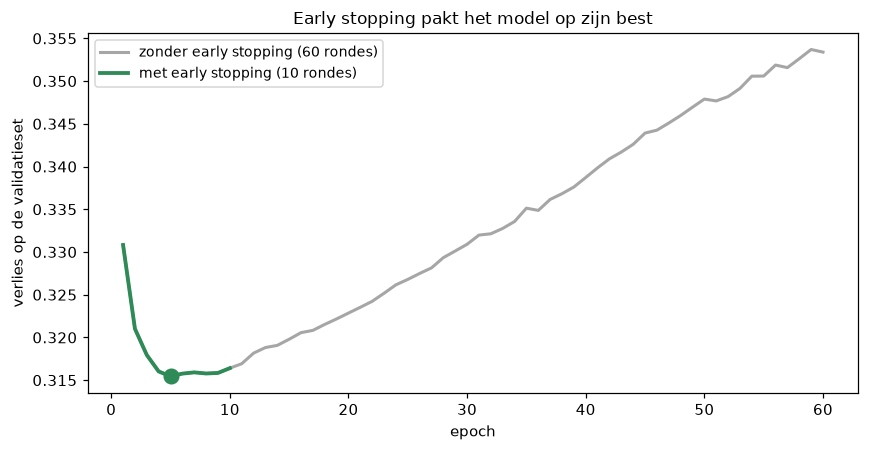

In [38]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(verloop.index, verloop["val_loss"], lw=2, color="0.65",
        label="zonder early stopping (60 rondes)")
ax.plot(verloop2.index, verloop2["val_loss"], lw=2.5, color="#2E8B57",
        label=f"met early stopping ({len(verloop2)} rondes)")
ax.scatter([verloop2["val_loss"].idxmin()], [verloop2["val_loss"].min()],
           s=90, color="#2E8B57", zorder=5)
ax.set_xlabel("epoch"); ax.set_ylabel("verlies op de validatieset")
ax.set_title("Early stopping pakt het model op zijn best", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---

## 13. En nu de eerlijke vergelijking

Alles ligt vast. Tijd voor de testset, die we tot nu toe niet hebben aangeraakt.

In [39]:
# De twee modellen uit deel 1 staan er al - niets opnieuw te trainen.
boom_score = accuracy_score(y_test, boom_eind.predict(X_test))
bos_score = accuracy_score(y_test, bos_eind.predict(X_test))

# Het netwerk met early stopping.
netwerk_score = netwerk2.evaluate(X_test_s, y_test, verbose=0)[1]

# Het netwerk dat we 60 rondes hebben laten doorploeteren.
overtraind_score = netwerk.evaluate(X_test_s, y_test, verbose=0)[1]

uitslag = pd.DataFrame({
    "op de testset": [1 - y_test.mean(), boom_score, bos_score,
                      overtraind_score, netwerk_score],
}, index=["altijd '<=50K' gokken (basislijn)",
          "beslisboom (deel 1)",
          "random forest (deel 1)",
          "netwerk, 60 rondes doorgetraind",
          "netwerk met early stopping"]).sort_values("op de testset")

display(uitslag.style.format("{:.2%}"))

print("Gesorteerd van slecht naar goed. Kijk waar het netwerk belandt.")

,op de testset
altijd '<=50K' gokken (basislijn),76.07%
"netwerk, 60 rondes doorgetraind",84.86%
netwerk met early stopping,85.39%
beslisboom (deel 1),86.20%
random forest (deel 1),86.70%


Gesorteerd van slecht naar goed. Kijk waar het netwerk belandt.


### Dit is de les van deze notebook

Kijk naar die tabel. Het neurale netwerk, met vierduizend parameters, verplichte schaling,
zestig trainingsrondes en een early-stoppingmechanisme, **verslaat geen van beide modellen uit
deel 1.** Niet de beslisboom, en al helemaal niet het random forest — dat met één regel code
gebouwd was, geen schaling nodig had en in anderhalve seconde klaar was.

Dat is geen fout in je code en geen ongeluk. Het is een bekend en goed onderzocht gegeven:

> **Op tabulaire data — rijen en kolommen, gemengd numeriek en categorisch — presteren
> boomgebaseerde modellen doorgaans even goed of beter dan neurale netwerken.**

Netwerken blinken uit waar de structuur ingewikkeld is en je zelf geen bruikbare kenmerken
kunt bedenken: beeld, geluid, taal. Bij een tabel met 12 kolommen is die structuur er niet.
Een boom kan daar direct op splitsen; een netwerk moet hetzelfde uit duizenden gewichten
afleiden.

Let ook op de derde regel: het netwerk dat we te lang lieten doorploeteren is slechter dan het
netwerk dat op tijd stopte. Meer trainen is niet meer leren.

**Wat je hiervan meeneemt:** begin altijd met het eenvoudige model. Niet omdat het eenvoudig
is, maar omdat je zonder dat vergelijkingspunt niet weet of je ingewikkelde model iets waard
is. Was dit netwerk je enige model geweest, dan had je 85% gezien en tevreden geknikt.

En let op wat je naast nauwkeurigheid nog meer inlevert: het netwerk kostte je schaling, een
keuze over lagen en neuronen, zestig trainingsrondes en een stopmechanisme. Het random forest
kostte je één regel. Bij gelijke uitkomst wint het eenvoudigste model altijd, want er is minder
dat stuk kan gaan.

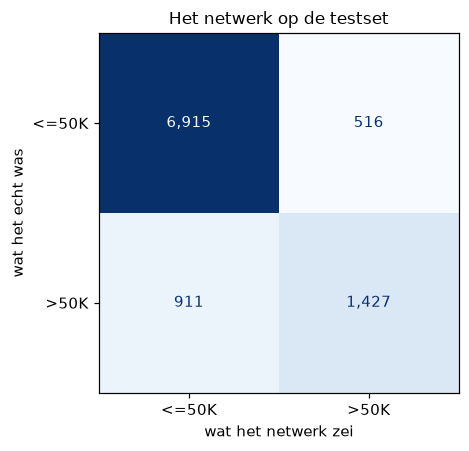

              precision    recall  f1-score   support

       <=50K      0.884     0.931     0.906      7431
        >50K      0.734     0.610     0.667      2338

    accuracy                          0.854      9769
   macro avg      0.809     0.770     0.787      9769
weighted avg      0.848     0.854     0.849      9769



In [40]:
voorspeld = (netwerk2.predict(X_test_s, verbose=0).ravel() > 0.5).astype(int)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, voorspeld, display_labels=["<=50K", ">50K"],
    cmap="Blues", colorbar=False, ax=ax, values_format=",d")
ax.set_xlabel("wat het netwerk zei"); ax.set_ylabel("wat het echt was")
ax.set_title("Het netwerk op de testset", fontsize=11)
plt.tight_layout(); plt.show()

print(classification_report(y_test, voorspeld, target_names=["<=50K", ">50K"], digits=3))

---

**Schalen is voor een netwerk verplicht.** Een boom kijkt naar "groter of kleiner dan"; een
netwerk vermenigvuldigt en telt op, en dan verpletteren grote getallen de kleine.

**Overfitting zie je in de grafiek gebeuren.** De trainlijn die blijft dalen terwijl de
validatielijn omhoog kruipt — dat beeld moet je herkennen.

**Ingewikkelder is niet beter.** Op deze data verslaan zowel de beslisboom als het random
forest het neurale netwerk. Dat weet je alleen omdat je de eenvoudige modellen eerst gebouwd
hebt.

> In **topic 2** vragen we aan deze modellen *waarom* ze iets voorspellen.